# 08 · Localization diagnosis, seed 42 (CP4 plan, 16 Nov 2026)

**L4.** It reads **validation data only** (the training pool's validation split, training editors): no test image. P2 is not scored.

- **Model:** unified seed 42, `best.pt`.
- **CLIP probe:** the unified probe (class token + patch probe). It is trained here once and cached in `runs/cp4/probes/`; notebook 09 reuses it.
- **Edited validation images (DiffSeg30k):**
  - whole images, tiled with full coverage;
  - edited and background IoU, pooled and per image;
  - over-marking and missing;
  - breakdowns by edit size, by editor and by base type;
  - the model against the patch probe;
  - the 16 × 16 and 64 × 64 resolution ceilings.
- **Real validation images:** the false "edited" rate and the marks, by tile count.
- **Training curves** of the mask metrics, from the CP3 `metrics.csv`.

Estimated cost about 1–1.5 compute units (most of it the probe training).

**Result** (send to Claude): `Paper 1/runs/checkpoints/localization_diagnosis_seed42.json`. Also written: the per-image CSVs and the plots in `Paper 1/runs/cp4/`.

In [1]:
# Cell 1: mount Drive, get the code, install it
import os, subprocess, sys

DRY = os.environ.get('EVIGROUND_DRY_RUN') == '1'   # CI / local test: fake sources, temp folders
REPO_URL = 'github.com/DHANUSHKUMMARI/Paper1.git'
BRANCH = 'main'                                    # 'claude/nice-curie-3tzxzr' before the merge

if DRY:
    REPO = os.path.abspath('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')
else:
    from google.colab import drive, userdata
    drive.mount('/content/drive')
    REPO = '/content/Paper1'
    if not os.path.exists(REPO):
        try:
            tok = userdata.get('GITHUB_TOKEN')       # never printed
        except Exception:
            tok = None
        url = f'https://{tok}@{REPO_URL}' if tok else f'https://{REPO_URL}'
        r = subprocess.run(['git', 'clone', '--depth', '1', '--branch', BRANCH, url, REPO],
                           capture_output=True, text=True)
        if r.returncode != 0:                        # stderr is not shown: it can contain the URL
            raise RuntimeError('git clone failed: check GITHUB_TOKEN (Secrets panel) and BRANCH')
        subprocess.run(['git', '-C', REPO, 'remote', 'set-url', 'origin', f'https://{REPO_URL}'],
                       check=True)
    else:
        subprocess.run(['git', '-C', REPO, 'pull', '--ff-only'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', REPO + '[train]'], check=True)
    # Colab ships torchao 0.10; peft refuses a torchao older than 0.16 with an ImportError when it
    # adds the LoRA layers, although EviGround never uses torchao: remove an old one.
    import importlib, importlib.metadata as _md
    from packaging.version import Version
    try:
        if Version(_md.version('torchao')) < Version('0.16.0'):
            subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', '-q', 'torchao'], check=True)
            importlib.invalidate_caches()
    except _md.PackageNotFoundError:
        pass

sys.path.insert(0, os.path.join(REPO, 'src'))
# Re-running in a runtime that already imported eviground would keep the OLD code in memory
# although git pulled the new one: drop it so the next import reads the files on disk.
for _name in [m for m in sys.modules if m == 'eviground' or m.startswith('eviground.')]:
    del sys.modules[_name]
print('repo:', REPO, '| branch:', BRANCH, '| dry run:', DRY)

Mounted at /content/drive
repo: /content/Paper1 | branch: main | dry run: False


In [2]:
# Cell 2: settings
DRY_DIR = 'eviground_locdiag_dry'
PROFILES = ['unified']

import csv, datetime, json, logging, os, time
from pathlib import Path
logging.basicConfig(level=logging.INFO, force=True)
import numpy as np, torch
from eviground.config import load_config
from eviground.data import pack
from eviground.env import get_paths, session_info
from eviground.eval import runner

CU_PER_HOUR = 1.94         # read the live rate in Colab's resource panel and update
SEED = 42
T0 = time.time()
info = session_info(cu_per_hour=CU_PER_HOUR)
paths = get_paths()
if DRY:   # fake world, tiny models, CPU
    import shutil, tempfile
    from eviground.env import Paths
    _dry = Path(tempfile.gettempdir()) / DRY_DIR
    shutil.rmtree(_dry, ignore_errors=True)
    paths = Paths(root=_dry / 'drive' / 'Paper 1', local_data=_dry / 'data')
paths.ensure()
CONFIG = 'debug' if DRY else 'base'
HF_CACHE = paths.cache / 'hf' if DRY else Path('/content/hf_cache')
OVERRIDES = [f'model.semantic.cache_dir={HF_CACHE}', f'compute.cu_per_hour={CU_PER_HOUR}']
cfg = load_config(CONFIG, OVERRIDES)
if not DRY:
    assert torch.cuda.is_available(), 'needs a GPU runtime (L4)'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EXPERIMENT = cfg.get('experiment', 'eviground')
CK = paths.runs / 'checkpoints'
OUT = paths.runs / 'cp4'
PROBES = OUT / 'probes'
PROBE_EPOCHS = 1 if DRY else 3
WORKERS = 0 if DRY else int(cfg.data.num_workers)
BATCH = 8 if DRY else 64
run_dir = lambda profile: paths.runs / f'{EXPERIMENT}_{profile}_seed{SEED}'
OUT.mkdir(parents=True, exist_ok=True); PROBES.mkdir(parents=True, exist_ok=True)
print('commit', info['git_commit'], '| gpu', info.get('gpu_name'), '| device', DEVICE)

INFO:eviground.env:session: python 3.13.16 | torch 2.14.1+cu130 | gpu NVIDIA L4 (23.7 GB) | drive mounted=True free=114.8 GB | commit c8ed936 | CU/h 1.94


commit c8ed936 | gpu NVIDIA L4 | device cuda


In [3]:
# Cell 3: shards (dry run: fake world and a tiny trained model)

SHARDS = paths.shards
CP1_RESULT = None
if DRY:   # fake world -> CP1 -> shards -> tiny trained models (one epoch each)
    from eviground.data.cp1 import CP1Config, run_cp1
    from eviground.data.download import ensure_data
    from eviground.data.fake_cp1 import cp1_overrides, make_cp1_world
    from eviground.train.trainer import Trainer
    sources = make_cp1_world(paths.datasets, paths.root.parent / 'fake_remote', coco_images=40)
    ensure_data('cp1', paths=paths, sources=sources, stage_local=True, overrides=cp1_overrides(40))
    CP1_RESULT = run_cp1(paths, CP1Config(workers=2, crops_per_class=60, blockiness_per_group=20,
                                          base_unclear_max=0.2, diffseg_card_splits={'train': 18, 'validation': 12}),
                         out_dir=CK / 'cp1', cache_dir=paths.cache / 'cp1', progress=None)
    pack.pack(CK / 'cp1' / 'manifest_cp1.csv.gz', SHARDS, free_bytes=10**12, margin=0,
              shard_bytes=200_000, sample_per_source=5, progress=None)
    for profile in PROFILES:
        Trainer(load_config(CONFIG, OVERRIDES + ['train.epochs=1']), SHARDS, run_dir(profile),
                seed=SEED, profile=profile, resume=None, log=None).fit()
LOCAL_SHARDS = paths.local_data / 'shards'
print(pack.stage_shards(SHARDS, LOCAL_SHARDS, progress=print))
SHARDS = LOCAL_SHARDS

INFO:numexpr.utils:NumExpr defaulting to 12 threads.


staging 18 of 18 shards (15.75 GB) to /content/data/shards
  1/18 coco/shard-00000.tar: 0.96 GB, 37 s
  2/18 diffseg30k/shard-00000.tar: 0.59 GB, 48 s
  3/18 diffseg30k/shard-00001.tar: 1.28 GB, 82 s
  4/18 diffseg30k/shard-00002.tar: 0.88 GB, 100 s
  5/18 diffseg30k/shard-00003.tar: 0.10 GB, 107 s
  6/18 genimage/shard-00000.tar: 1.07 GB, 130 s
  7/18 genimage/shard-00001.tar: 1.02 GB, 150 s
  8/18 genimage/shard-00002.tar: 1.02 GB, 172 s
  9/18 genimage/shard-00003.tar: 1.00 GB, 194 s
  10/18 genimage/shard-00004.tar: 1.01 GB, 216 s
  11/18 genimage/shard-00005.tar: 1.07 GB, 241 s
  12/18 genimage/shard-00006.tar: 0.90 GB, 257 s
  13/18 genimage/shard-00007.tar: 0.94 GB, 272 s
  14/18 genimage/shard-00008.tar: 0.90 GB, 290 s
  15/18 genimage/shard-00009.tar: 0.91 GB, 304 s
  16/18 genimage/shard-00010.tar: 0.17 GB, 315 s
  17/18 sidset/shard-00000.tar: 0.94 GB, 330 s
  18/18 sidset/shard-00001.tar: 1.00 GB, 343 s
{'local_dir': '/content/data/shards', 'shards': 18, 'copied': 18, 'skip

In [4]:
# Cell 4: the trained unified model
BEST = run_dir('unified') / 'best.pt'
model = runner.load_trained(cfg.model, BEST, DEVICE)
print('loaded', BEST)

from eviground.baselines import clip_probe

def get_probe(profile, model):
    '''The cached probe of ``profile``, or train it (the model's frozen CLIP, LoRA off).'''
    path = PROBES / f'probe_{profile}.pt'
    if path.is_file():
        saved = torch.load(path, weights_only=True)
        print('probe reused:', path)
        return clip_probe.ProbeHead.from_state(saved['head']).to(DEVICE), saved['report']
    tc = dict(cfg.train)
    crops = int((tc.get('detection') or {}).get('crops_per_epoch', 16000)) if profile == 'detection' else int(tc['crops_per_epoch'])
    train_b, val_b = runner.probe_data(SHARDS, profile=profile, crop=int(cfg.data.crop),
                                       crops_per_epoch=crops, epochs=PROBE_EPOCHS, seed=SEED,
                                       batch=BATCH, workers=WORKERS, augment_cfg=cfg.data.get('augment'))
    t = time.time()
    head, report = clip_probe.train_probes(model, train_b(), val_b, profile=profile, device=DEVICE)
    report['minutes'] = round((time.time() - t) / 60, 2)
    torch.save({'head': head.state(), 'report': report}, path)
    return head.to(DEVICE), report

probe_head, probe_report = get_probe('unified', model)
print(json.dumps(probe_report, indent=1, default=str)[:2000])

INFO:httpx:HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/openai/clip-vit-large-patch14/resolve/32bd64288804d66eefd0ccbe215aa642df71cc41/model.safetensors "HTTP/1.1 302 Found"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-large-patch14/xet-read-token/32bd64288804d66eefd0ccbe215aa642df71cc41 "HTTP/1.1 200 OK"


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:httpx:HTTP Request: HEAD https://huggingface.co/openai/clip-vit-large-patch14/resolve/32bd64288804d66eefd0ccbe215aa642df71cc41/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/openai/clip-vit-large-patch14/32bd64288804d66eefd0ccbe215aa642df71cc41/config.json?%2Fopenai%2Fclip-vit-large-patch14%2Fresolve%2F32bd64288804d66eefd0ccbe215aa642df71cc41%2Fconfig.json=&etag=%222c19f6666e0e163c7954df66cb901353fcad088e%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/resolve-cache/models/openai/clip-vit-large-patch14/32bd64288804d66eefd0ccbe215aa642df71cc41/config.json?%2Fopenai%2Fclip-vit-large-patch14%2Fresolve%2F32bd64288804d66eefd0ccbe215aa642df71cc41%2Fconfig.json=&etag=%222c19f6666e0e163c7954df66cb901353fcad088e%22 "HTTP/1.1 200 OK"


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

... (3 outputs left out)

INFO:timm.models._hub:[timm/efficientnet_b0.ra_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
INFO:timm.models._builder:Converted input conv conv_stem pretrained weights from 3 to 4 channel(s)


loaded /content/drive/MyDrive/Paper 1/runs/eviground_unified_seed42/best.pt


INFO:eviground.data.datasets:train: 126 edited images without a valid crop left out
INFO:eviground.data.datasets:val: 14 edited images without a valid crop left out


probe unified: {'profile': 'unified', 'train_crops': 72000, 'val_crops': 11689, 'class_token': {'l2': 0.001, 'val_auc': 0.9784117913657092, 'tried': [{'l2': 0.0001, 'val_auc': 0.978389652883289}, {'l2': 0.001, 'val_auc': 0.9784117913657092}, {'l2': 0.01, 'val_auc': 0.9770548317170725}, {'l2': 0.1, 'val_auc': 0.9682918171962043}, {'l2': 1.0, 'val_auc': 0.9458829955606592}, {'l2': 10.0, 'val_auc': 0.908276168547185}]}, 'patch': {'l2': 0.0, 'val_mask_f1': 0.24712872505187988, 'tried': [{'l2': 0.0, 'val_mask_f1': 0.24712872505187988}, {'l2': 1e-05, 'val_mask_f1': 0.2470957189798355}, {'l2': 0.0001, 'val_mask_f1': 0.24677692353725433}, {'l2': 0.001, 'val_mask_f1': 0.24355919659137726}, {'l2': 0.01, 'val_mask_f1': 0.21485288441181183}, {'l2': 0.1, 'val_mask_f1': 0.0714787021279335}]}}
{
 "profile": "unified",
 "train_crops": 72000,
 "val_crops": 11689,
 "class_token": {
  "l2": 0.001,
  "val_auc": 0.9784117913657092,
  "tried": [
   {
    "l2": 0.0001,
    "val_auc": 0.978389652883289
   },


In [5]:
# Cell 5: the diagnosis pass (whole validation images: DiffSeg30k edited, and every real image)
from eviground.data.pack import read_index
from eviground.eval import testsets
rows = [r for r in read_index(SHARDS / 'index.parquet') if r['split'] == 'val'
        and ((r['source'] == 'diffseg30k' and r['label'] == 'edited') or r['label'] == 'real')]
if DRY:   # the fake world has no edited validation image: training ones stand in (dry run only)
    rows += [r for r in read_index(SHARDS / 'index.parquet') if r['split'] == 'train' and r['label'] == 'edited']
print(len(rows), 'validation images:', sum(r['label'] == 'edited' for r in rows), 'edited,',
      sum(r['label'] == 'real' for r in rows), 'real')
predict = runner.joint_predictor(model, probe_head, DEVICE)
tick = lambda n: print(f'  {n} images', flush=True) if n % 500 == 0 else None
DIAG = runner.diagnosis_pass(predict, testsets.shard_items(SHARDS, rows), DEVICE, progress=tick)
print(DIAG['stats'])

6722 validation images: 1177 edited, 5545 real
  500 images
  1000 images
  1500 images
  2000 images
  2500 images
  3000 images
  3500 images


/content/Paper1/src/eviground/eval/tiled.py:100: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  crops.append(torch.from_numpy(np.ascontiguousarray(p["item"].image[t:b, le:r])))


  4000 images
  4500 images
  5000 images
  5500 images
  6000 images
  6500 images
{'images': 6722, 'tiles': 50843, 'max_tiles': 169, 'seconds': 1876.6}


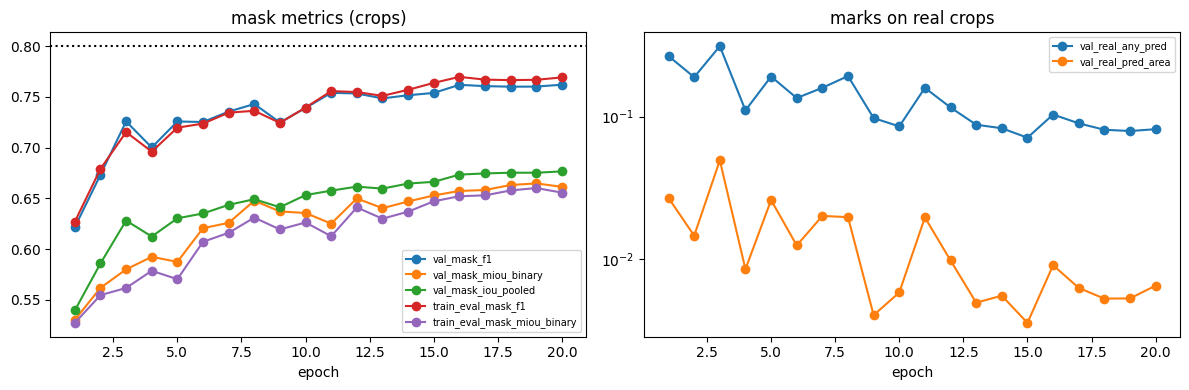

{
 "model": {
  "images": 1177,
  "iou_edited": 0.3945986206388521,
  "iou_background": 0.5614743615570327,
  "miou_diffseg30k": 0.3945986206388521,
  "miou_two_class": 0.4780364910979424,
  "f1_pooled": 0.5658956129729862,
  "pixel_acc": 0.6589550817083513,
  "fp_share_of_pixels": 0.28863003634167256,
  "fn_share_of_edited": 0.190802977869551,
  "auc_pixel": 0.8008340744618615,
  "mean_iou_per_image": 0.5214355571224177,
  "mean_f1_per_image": 0.6424819499522489,
  "mean_boundary_f1": 0.159971598592752,
  "called_edited_area_rule": 0.994052676295667
 },
 "probe": {
  "images": 1177,
  "iou_edited": 0.1527193964602597,
  "iou_background": 0.7019037409522816,
  "miou_diffseg30k": 0.1527193964602597,
  "miou_two_class": 0.42731156870627063,
  "f1_pooled": 0.26497237216485886,
  "pixel_acc": 0.7171039760185972,
  "fp_share_of_pixels": 0.05918021933389079,
  "fn_share_of_edited": 0.8143801938534635,
  "auc_pixel": 0.6449362320776229,
  "mean_iou_per_image": 0.1478285028974125,
  "mean_f1_p

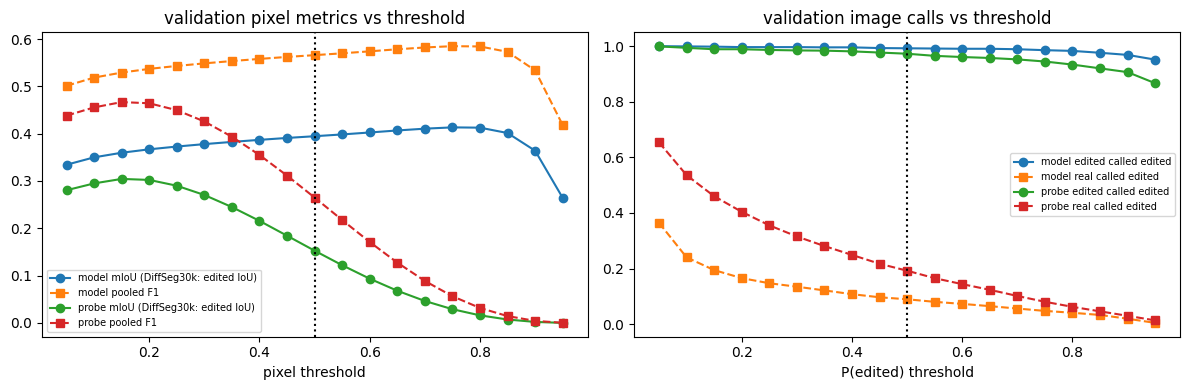

In [6]:
# Cell 6: summaries, per-image CSVs, curves
from eviground.eval import locdiag, cp3
from eviground.eval.tiled import per_image
heads = ['model', 'probe']
EDITED = locdiag.summarize_edited(DIAG['edited'], heads)
REAL = locdiag.summarize_real(DIAG['real'], heads)
with open(OUT / 'diagnosis_edited_seed42.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['uid', 'share', 'editors', 'base_type', 'tiles', 'model_iou', 'model_f1', 'model_boundary_f1',
                'probe_iou', 'probe_f1', 'ceiling16_iou', 'ceiling64_iou'])
    for r in DIAG['edited']:
        m, p = per_image(r['heads']['model']), per_image(r['heads']['probe'])
        c16, c64 = per_image(r['ceilings'][16]), per_image(r['ceilings'][64])
        w.writerow([r['uid'], round(r['share'], 5), '|'.join(r['editors']), r['base_type'], r['tiles'],
                    m['iou'], m['f1'], m['boundary_f1'], p['iou'], p['f1'], c16['iou'], c64['iou']])
with open(OUT / 'diagnosis_real_seed42.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['uid', 'source', 'tiles', 'model_label', 'model_marked', 'probe_label', 'probe_marked'])
    for r in DIAG['real']:
        h = r['heads']
        w.writerow([r['uid'], r['source'], r['tiles'], h['model']['label'], round(h['model']['marked_share'], 6),
                    h['probe']['label'], round(h['probe']['marked_share'], 6)])
metrics_rows = cp3.read_csv(run_dir('unified') / 'metrics.csv')
best = cp3.best_row(metrics_rows)
CURVE_KEYS = ['val_mask_f1', 'val_mask_miou_binary', 'val_mask_iou_pooled', 'train_eval_mask_f1',
              'train_eval_mask_miou_binary', 'val_real_any_pred', 'val_real_pred_area']
CURVES = {k: [None if r.get(k) in (None, '') else float(r[k]) for r in metrics_rows] for k in CURVE_KEYS}
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ep = list(range(1, len(metrics_rows) + 1))
    for k in CURVE_KEYS[:5]:
        ax[0].plot(ep, CURVES[k], 'o-', label=k)
    ax[0].axhline(0.80, ls=':', c='k'); ax[0].set_xlabel('epoch'); ax[0].legend(fontsize=7); ax[0].set_title('mask metrics (crops)')
    for k in CURVE_KEYS[5:]:
        ax[1].plot(ep, CURVES[k], 'o-', label=k)
    ax[1].set_yscale('symlog', linthresh=0.01); ax[1].set_xlabel('epoch'); ax[1].legend(fontsize=7); ax[1].set_title('marks on real crops')
    fig.tight_layout(); fig.savefig(OUT / 'diagnosis_curves_seed42.png', dpi=110); plt.show()
except ImportError:
    print('matplotlib not installed: no plot')
print(json.dumps({h: EDITED[h]['all'] for h in heads}, indent=1, default=str))
print(json.dumps(EDITED.get('ceilings', {}).get('grid_16', {}).get('all'), indent=1))
# validation-only threshold sweep (diagnostic: headline numbers and the gate stay at 0.5)
from eviground.eval import thresholds
SWEEP = thresholds.diagnosis_sweeps(DIAG['edited'], DIAG['real'], heads, tile_bin=locdiag.tile_bin)
for h in heads:
    print(h, json.dumps(SWEEP[h]['best'], default=str))
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for h in heads:
        px = SWEEP[h]['pixel']
        t = [r['threshold'] for r in px]
        ax[0].plot(t, [r['miou_diffseg30k'] for r in px], 'o-', label=f'{h} mIoU (DiffSeg30k: edited IoU)')
        ax[0].plot(t, [r['f1_pooled'] for r in px], 's--', label=f'{h} pooled F1')
        im = SWEEP[h]['image']
        ti = [r['threshold'] for r in im]
        ax[1].plot(ti, [r['edited_called_edited'] for r in im], 'o-', label=f'{h} edited called edited')
        ax[1].plot(ti, [r['real_called_edited'] for r in im], 's--', label=f'{h} real called edited')
    ax[0].axvline(0.5, ls=':', c='k'); ax[0].set_xlabel('pixel threshold'); ax[0].legend(fontsize=7)
    ax[0].set_title('validation pixel metrics vs threshold')
    ax[1].axvline(0.5, ls=':', c='k'); ax[1].set_xlabel('P(edited) threshold'); ax[1].legend(fontsize=7)
    ax[1].set_title('validation image calls vs threshold')
    fig.tight_layout(); fig.savefig(OUT / 'diagnosis_threshold_sweep_seed42.png', dpi=110); plt.show()
except ImportError:
    print('matplotlib not installed: no plot')

In [7]:
# Cell 7: the result file
hours = (time.time() - T0) / 3600
RESULT = {
    'step': 'Localization diagnosis (validation only)', 'dry_run': DRY, 'branch': BRANCH, 'seed': SEED,
    'session': info, 'config': CONFIG, 'model': str(BEST),
    'probe': probe_report, 'pass': DIAG['stats'],
    'edited': EDITED, 'real': REAL,
    'crop_vs_full': {
        # DiffSeg30k definition (background excluded): CP3's pooled edited IoU on crops vs whole images
        'cp3_best_epoch_crop_miou_diffseg30k': None if best is None else cp3._num(best.get('val_mask_iou_pooled')),
        'full_image_miou_diffseg30k': EDITED['model']['all']['miou_diffseg30k'],
        # the two-class mean (edited and background IoU) recorded in CP3 as R2
        'cp3_best_epoch_crop_miou_two_class': None if best is None else cp3._num(best.get('val_mask_miou_binary')),
        'full_image_miou_two_class': EDITED['model']['all']['miou_two_class'],
    },
    'curves': CURVES,
    'threshold_sweep': SWEEP,
    'utc': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
    'wall_time_h': round(hours, 3), 'cu_per_hour': CU_PER_HOUR, 'compute_units': round(hours * CU_PER_HOUR, 2),
    'definitions': {
        'source': 'DiffSeg30k, arXiv 2511.19111v2, sections 4.1-4.2 (checked 17 Nov 2026)',
        'miou_diffseg30k': 'edited-class IoU; background excluded as in the paper; pooled over pixels (the paper does not state its averaging)',
        'miou_two_class': 'mean of edited and background IoU (our earlier definition, kept for continuity with CP3 R2)',
        'boundary_f1': 'edited-class boundary only (background excluded as in the paper); 4-neighbour boundary, 2 px tolerance (the paper does not state a tolerance)',
        'called_edited_area_rule': 'the paper\'s image rule: edited when more than 1% of the image is predicted edited (pixel threshold 0.5)',
    },
}
out = CK / 'localization_diagnosis_seed42.json'
out.write_text(json.dumps(RESULT, indent=1, default=str))
if DRY:   # the sweep block is there for both heads, with the 0.5 reference beside each best
    for h in heads:
        assert SWEEP[h]['pixel'] and SWEEP[h]['image'], h
        assert abs(SWEEP[h]['best']['miou_diffseg30k']['default_threshold'] - 0.5) < 1e-9, h
        assert 'called_edited_area_rule' in EDITED[h]['all'] and 'called_edited_area_rule' in REAL[h]['all'], h
print('saved', out, '| CU', RESULT['compute_units'])

saved /content/drive/MyDrive/Paper 1/runs/checkpoints/localization_diagnosis_seed42.json | CU 1.6
